# 🤖 Notebook 3: Model Building & Evaluation
**HR Employee Attrition Project**

**Objective:** Train classification models to predict which employees are likely to leave. Evaluate models rigorously using multiple metrics beyond just accuracy.

---

## 1. Setup & Load Cleaned Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)
from sklearn.preprocessing import StandardScaler

import os
for d in ('models','reports'):
    os.makedirs(d, exist_ok=True)

sns.set_theme(style='whitegrid')

df = pd.read_csv('data/cleaned_hr_data.csv')
print(f'Cleaned dataset loaded: {df.shape}')
df.head(2)

Cleaned dataset loaded: (1470, 48)


## 2. Prepare Features & Target

In [2]:
X = df.drop('Attrition', axis=1)
y = df['Attrition'].map({'Yes': 1, 'No': 0})
print(f'Features: {X.shape[1]}')
print(f'Target distribution:')
print(y.value_counts())
print(f'\nAttrition rate: {y.mean()*100:.1f}%')

Features: 47
Target distribution:
Attrition
0    1233
1     237
Name: count, dtype: int64

Attrition rate: 16.1%


## 3. Train/Test Split

In [3]:
# Stratified split ensures both sets maintain the same attrition ratio
X = df.drop('Attrition', axis=1)
y = df['Attrition'].map({'Yes': 1, 'No': 0})
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training set: {X_train.shape[0]} rows')
print(f'Test set: {X_test.shape[0]} rows')
print(f'Train attrition rate: {y_train.mean()*100:.1f}%')
print(f'Test attrition rate: {y_test.mean()*100:.1f}%')

Training set: 1176 rows
Test set: 294 rows
Train attrition rate: 16.2%
Test attrition rate: 16.0%


## 4. Scale Features (for Logistic Regression)

In [4]:
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

In [5]:
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

In [6]:
from sklearn.preprocessing import StandardScaler
import joblib

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

joblib.dump(scaler, 'models/scaler.pkl')
print("Scaler fitted and saved.")

Scaler fitted and saved.


## 5. Model 1 — Logistic Regression (Baseline)
Good for: Interpretability and establishing a baseline. Coefficients tell us the direction of each feature's influence.

In [7]:
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]

print('=== Logistic Regression Results ===')
print(f'Accuracy:  {accuracy_score(y_test, y_pred_lr):.4f}')
print(f'Precision: {precision_score(y_test, y_pred_lr):.4f}')
print(f'Recall:    {recall_score(y_test, y_pred_lr):.4f}')
print(f'F1 Score:  {f1_score(y_test, y_pred_lr):.4f}')
print(f'ROC-AUC:   {roc_auc_score(y_test, y_prob_lr):.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_lr, target_names=['Stayed', 'Left']))

=== Logistic Regression Results ===
Accuracy:  0.7585
Precision: 0.3605
Recall:    0.6596
F1 Score:  0.4662
ROC-AUC:   0.7950

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.92      0.78      0.84       247
        Left       0.36      0.66      0.47        47

    accuracy                           0.76       294
   macro avg       0.64      0.72      0.66       294
weighted avg       0.83      0.76      0.78       294



## 6. Model 2 — Random Forest (Main Model)
Good for: Capturing non-linear relationships, interactions between features, and providing feature importance.

In [8]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print('=== Random Forest Results ===')
print(f'Accuracy:  {accuracy_score(y_test, y_pred_rf):.4f}')
print(f'Precision: {precision_score(y_test, y_pred_rf):.4f}')
print(f'Recall:    {recall_score(y_test, y_pred_rf):.4f}')
print(f'F1 Score:  {f1_score(y_test, y_pred_rf):.4f}')
print(f'ROC-AUC:   {roc_auc_score(y_test, y_prob_rf):.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_rf, target_names=['Stayed', 'Left']))

=== Random Forest Results ===
Accuracy:  0.8265
Precision: 0.4444
Recall:    0.3404
F1 Score:  0.3855
ROC-AUC:   0.7791

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.88      0.92      0.90       247
        Left       0.44      0.34      0.39        47

    accuracy                           0.83       294
   macro avg       0.66      0.63      0.64       294
weighted avg       0.81      0.83      0.82       294



## 7. Model Comparison — Confusion Matrices

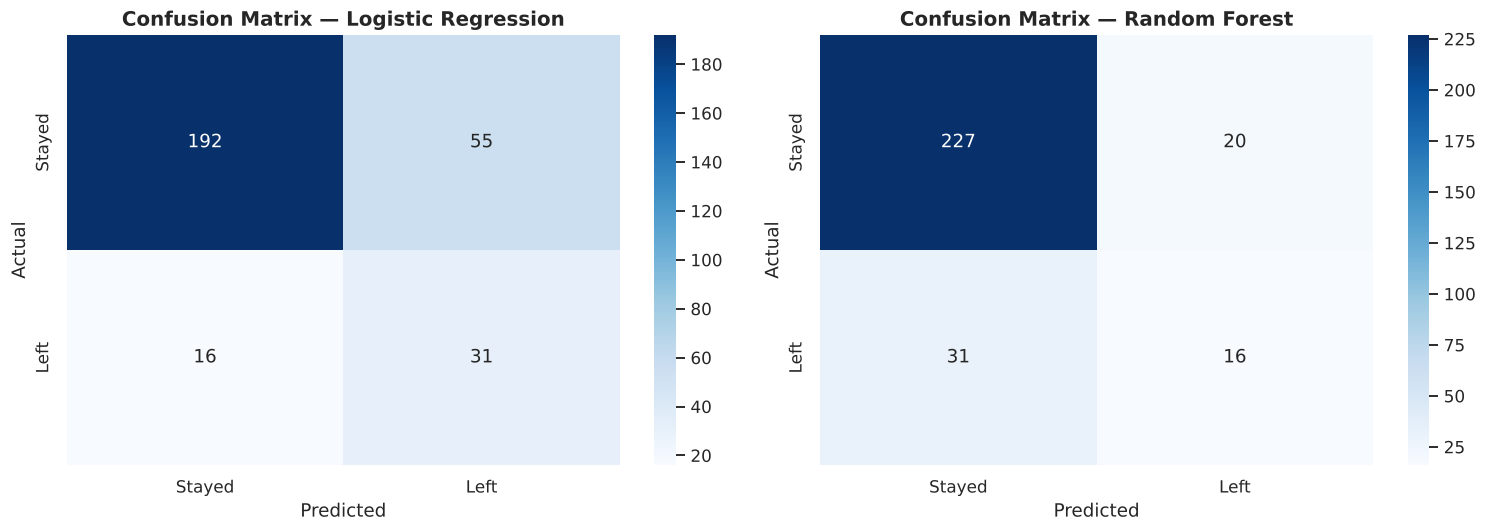

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, y_pred, title in [
    (axes[0], y_pred_lr, 'Logistic Regression'),
    (axes[1], y_pred_rf, 'Random Forest')
]:
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Stayed', 'Left'],
                yticklabels=['Stayed', 'Left'])
    ax.set_title(f'Confusion Matrix — {title}', fontsize=13, fontweight='bold')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.tight_layout()
plt.savefig('reports/fig9_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. ROC Curve Comparison

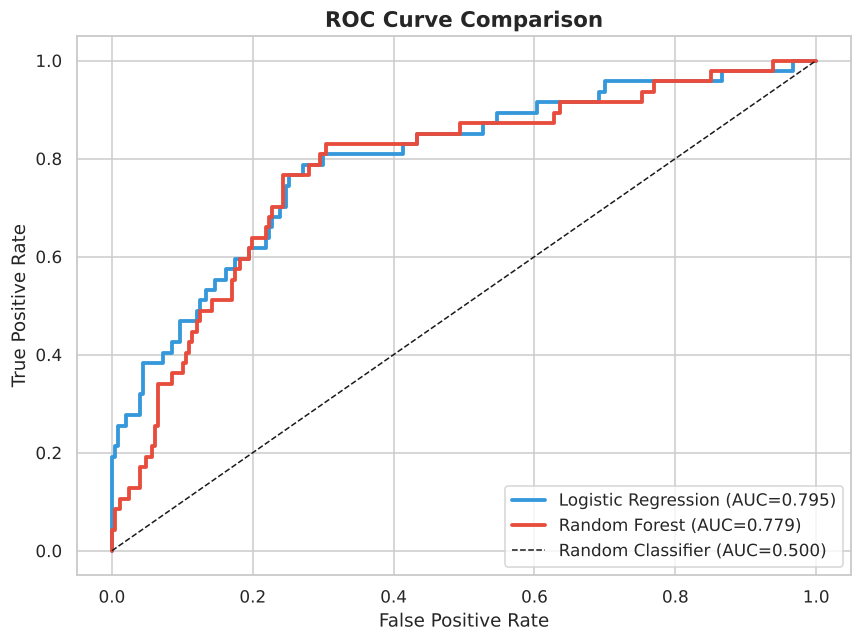

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))

for y_prob, label, color in [
    (y_prob_lr, f'Logistic Regression (AUC={roc_auc_score(y_test, y_prob_lr):.3f})', '#3498db'),
    (y_prob_rf, f'Random Forest (AUC={roc_auc_score(y_test, y_prob_rf):.3f})', '#e74c3c')
]:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    ax.plot(fpr, tpr, label=label, color=color, linewidth=2.5)

ax.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC=0.500)', linewidth=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve Comparison', fontsize=14, fontweight='bold')
ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig('reports/fig10_roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Cross Validation

In [11]:
cv_scores_lr = cross_val_score(lr, X_train_scaled, y_train, cv=5, scoring='roc_auc')
cv_scores_rf = cross_val_score(rf, X_train, y_train, cv=5, scoring='roc_auc')

print('5-Fold Cross Validation ROC-AUC:')
print(f'Logistic Regression: {cv_scores_lr.mean():.4f} ± {cv_scores_lr.std():.4f}')
print(f'Random Forest:       {cv_scores_rf.mean():.4f} ± {cv_scores_rf.std():.4f}')

5-Fold Cross Validation ROC-AUC:
Logistic Regression: 0.8264 ± 0.0546
Random Forest:       0.7909 ± 0.0623


## Results summary

Evaluated on a stratified 20% hold-out set (294 employees, 47 who left; overall attrition rate 16.1%). Both models use `class_weight='balanced'` because only about 1 in 6 employees leaves.

| Model | Accuracy | Precision (Left) | Recall (Left) | F1 (Left) | ROC-AUC | 5-fold CV ROC-AUC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.759 | 0.361 | 0.660 | 0.466 | 0.795 | 0.826 ± 0.055 |
| Random Forest | 0.827 | 0.444 | 0.340 | 0.386 | 0.779 | 0.791 ± 0.062 |

**How to read this:** accuracy alone is misleading with 16% positives. The Random Forest is more accurate overall but finds only 16 of the 47 leavers, while the logistic regression baseline finds about two thirds of them at the cost of more false alarms. Which is better depends on whether HR prefers fewer missed leavers or fewer false flags. Next steps would be threshold tuning and hyperparameter search.

*An earlier version of this notebook showed 1.0000 for every metric. The stored run used 48 features instead of the 47 produced by the current data, so an extra column, most likely one that encoded the answer, was present. The notebook was re-run from a clean state and the feature set was verified.*


## 10. Save Best Model

In [12]:
# Save the models and the exact encoded feature names the Random Forest was trained on
joblib.dump(rf, 'models/rf_attrition_model.pkl')
joblib.dump(lr, 'models/lr_attrition_model.pkl')
joblib.dump(list(X_train.columns), 'models/feature_names.pkl')

print('Models saved to models/')
print(f'Features saved: {X_train.shape[1]} features')


Models saved to models/
Features saved: 46 features
